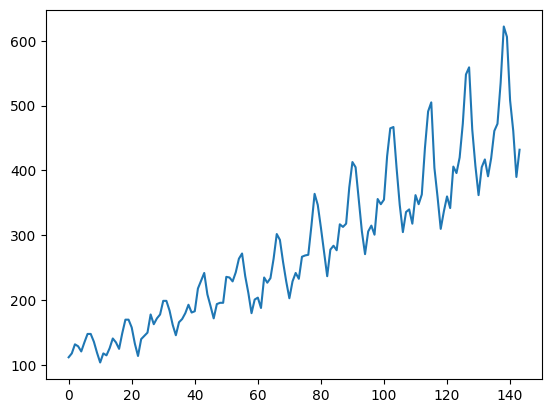

In [2]:
import matplotlib.pyplot as plt
import pandas as pd

df = pd.read_csv('airline-passengers.csv')
timeseries = df[["Passengers"]].values.astype('float32')

plt.plot(timeseries)
plt.show()

In [3]:
# train-test split for time series
train_size = int(len(timeseries) * 0.67)
test_size = len(timeseries) - train_size
train, test = timeseries[:train_size], timeseries[train_size:]

import torch

def create_dataset(dataset, lookback):
    """Transform a time series into a prediction dataset

    Args:
        dataset: A numpy array of time series, first dimension is the time steps
        lookback: Size of window for prediction
    """
    X, y = [], []
    for i in range(len(dataset)-lookback):
        feature = dataset[i:i+lookback]
        target = dataset[i+1:i+lookback+1]
        X.append(feature)
        y.append(target)
    return torch.tensor(X), torch.tensor(y)

lookback = 1
X_train, y_train = create_dataset(train, lookback=lookback)
X_test, y_test = create_dataset(test, lookback=lookback)
print(X_train.shape, y_train.shape)
print(X_test.shape, y_test.shape)

torch.Size([95, 1, 1]) torch.Size([95, 1, 1])
torch.Size([47, 1, 1]) torch.Size([47, 1, 1])


C:\Users\MSI GAMING\AppData\Local\Temp\ipykernel_30396\2649542906.py:21: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\torch\csrc\utils\tensor_new.cpp:255.)
  return torch.tensor(X), torch.tensor(y)


In [4]:
import torch.nn as nn

class AirModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.lstm = nn.LSTM(input_size=1, hidden_size=50, num_layers=1, batch_first=True)
        self.linear = nn.Linear(50, 1)

    def forward(self, x):
        x, _ = self.lstm(x)
        x = self.linear(x)
        return x

In [5]:
import numpy as np
import torch.optim as optim
import torch.utils.data as data

model = AirModel()
optimizer = optim.Adam(model.parameters())
loss_fn = nn.MSELoss()
loader = data.DataLoader(data.TensorDataset(X_train, y_train), shuffle=True, batch_size=8)

n_epochs = 2000
for epoch in range(n_epochs):
    model.train()
    for X_batch, y_batch in loader:
        y_pred = model(X_batch)
        loss = loss_fn(y_pred, y_batch)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    # Validation
    if epoch % 100 != 0:
        continue
    model.eval()
    with torch.no_grad():
        y_pred = model(X_train)
        train_rmse = np.sqrt(loss_fn(y_pred, y_train))
        y_pred = model(X_test)
        test_rmse = np.sqrt(loss_fn(y_pred, y_test))
    print("Epoch %d: train RMSE %.4f, test RMSE %.4f" % (epoch, train_rmse, test_rmse))

C:\Users\MSI GAMING\AppData\Local\Temp\ipykernel_30396\2136496989.py:25: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  train_rmse = np.sqrt(loss_fn(y_pred, y_train))
C:\Users\MSI GAMING\AppData\Local\Temp\ipykernel_30396\2136496989.py:27: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  test_rmse = np.sqrt(loss_fn(y_pred, y_test))


Epoch 0: train RMSE 226.0079, test RMSE 422.4107
Epoch 100: train RMSE 189.3484, test RMSE 384.0937
Epoch 200: train RMSE 159.7807, test RMSE 352.4078
Epoch 300: train RMSE 133.4264, test RMSE 323.0161
Epoch 400: train RMSE 110.5920, test RMSE 295.7022
Epoch 500: train RMSE 92.2689, test RMSE 270.8398
Epoch 600: train RMSE 76.1813, test RMSE 247.3855
Epoch 700: train RMSE 62.3217, test RMSE 224.8614
Epoch 800: train RMSE 51.4109, test RMSE 204.2805
Epoch 900: train RMSE 42.9902, test RMSE 185.6741
Epoch 1000: train RMSE 36.9313, test RMSE 169.1803
Epoch 1100: train RMSE 32.7902, test RMSE 154.8616
Epoch 1200: train RMSE 30.2893, test RMSE 142.3531
Epoch 1300: train RMSE 27.3565, test RMSE 132.6726
Epoch 1400: train RMSE 27.5229, test RMSE 124.4567
Epoch 1500: train RMSE 25.2177, test RMSE 118.3712
Epoch 1600: train RMSE 25.0423, test RMSE 113.1421
Epoch 1700: train RMSE 25.0482, test RMSE 109.1903
Epoch 1800: train RMSE 23.8190, test RMSE 106.2770
Epoch 1900: train RMSE 23.8740, test R

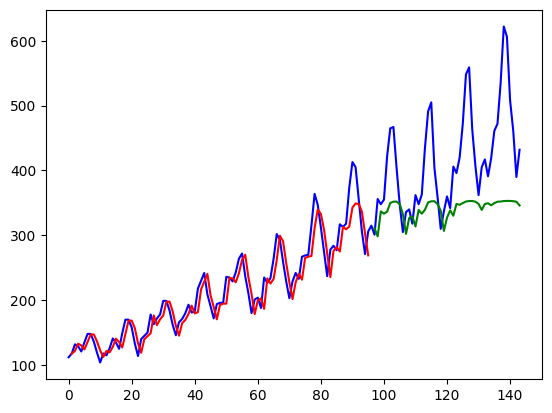

In [6]:
with torch.no_grad():
    # shift train predictions for plotting
    train_plot = np.ones_like(timeseries) * np.nan
    y_pred = model(X_train)
    y_pred = y_pred[:, -1, :]
    train_plot[lookback:train_size] = model(X_train)[:, -1, :]
    # shift test predictions for plotting
    test_plot = np.ones_like(timeseries) * np.nan
    test_plot[train_size+lookback:len(timeseries)] = model(X_test)[:, -1, :]
# plot
plt.plot(timeseries, c='b')
plt.plot(train_plot, c='r')
plt.plot(test_plot, c='g')
plt.show()

C:\Users\MSI GAMING\AppData\Local\Temp\ipykernel_30396\126727746.py:67: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  train_rmse = np.sqrt(loss_fn(y_pred, y_train))
C:\Users\MSI GAMING\AppData\Local\Temp\ipykernel_30396\126727746.py:69: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  test_rmse = np.sqrt(loss_fn(y_pred, y_test))


Epoch 0: train RMSE 225.9840, test RMSE 425.2455
Epoch 100: train RMSE 177.6681, test RMSE 374.5416
Epoch 200: train RMSE 140.0117, test RMSE 333.2987
Epoch 300: train RMSE 109.8094, test RMSE 297.2157
Epoch 400: train RMSE 87.6529, test RMSE 266.0898
Epoch 500: train RMSE 67.4739, test RMSE 235.3659
Epoch 600: train RMSE 53.0982, test RMSE 207.8796
Epoch 700: train RMSE 42.7907, test RMSE 184.1179
Epoch 800: train RMSE 35.7652, test RMSE 162.9381
Epoch 900: train RMSE 30.6062, test RMSE 144.9579
Epoch 1000: train RMSE 27.2271, test RMSE 130.1595
Epoch 1100: train RMSE 25.1687, test RMSE 117.6264
Epoch 1200: train RMSE 23.9604, test RMSE 107.8129
Epoch 1300: train RMSE 22.5764, test RMSE 100.6284
Epoch 1400: train RMSE 21.8182, test RMSE 94.3678
Epoch 1500: train RMSE 21.7751, test RMSE 89.4787
Epoch 1600: train RMSE 20.8515, test RMSE 85.1315
Epoch 1700: train RMSE 20.3205, test RMSE 82.2048
Epoch 1800: train RMSE 19.8611, test RMSE 80.0463
Epoch 1900: train RMSE 19.7257, test RMSE 78

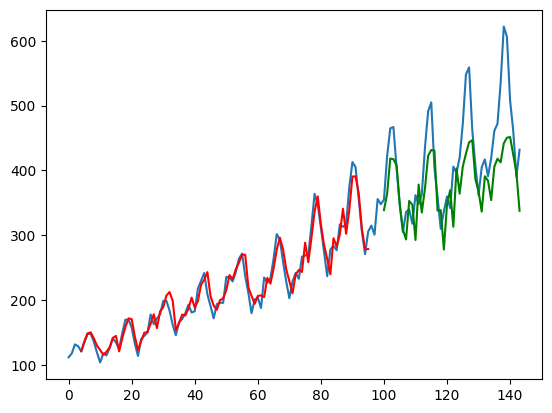

In [7]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
import torch.utils.data as data

df = pd.read_csv('airline-passengers.csv')
timeseries = df[["Passengers"]].values.astype('float32')

# train-test split for time series
train_size = int(len(timeseries) * 0.67)
test_size = len(timeseries) - train_size
train, test = timeseries[:train_size], timeseries[train_size:]

def create_dataset(dataset, lookback):
    """Transform a time series into a prediction dataset

    Args:
        dataset: A numpy array of time series, first dimension is the time steps
        lookback: Size of window for prediction
    """
    X, y = [], []
    for i in range(len(dataset)-lookback):
        feature = dataset[i:i+lookback]
        target = dataset[i+1:i+lookback+1]
        X.append(feature)
        y.append(target)
    return torch.tensor(X), torch.tensor(y)

lookback = 4
X_train, y_train = create_dataset(train, lookback=lookback)
X_test, y_test = create_dataset(test, lookback=lookback)

class AirModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.lstm = nn.LSTM(input_size=1, hidden_size=50, num_layers=1, batch_first=True)
        self.linear = nn.Linear(50, 1)

    def forward(self, x):
        x, _ = self.lstm(x)
        x = self.linear(x)
        return x

model = AirModel()
optimizer = optim.Adam(model.parameters())
loss_fn = nn.MSELoss()
loader = data.DataLoader(data.TensorDataset(X_train, y_train), shuffle=True, batch_size=8)

n_epochs = 2000
for epoch in range(n_epochs):
    model.train()
    for X_batch, y_batch in loader:
        y_pred = model(X_batch)
        loss = loss_fn(y_pred, y_batch)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    # Validation
    if epoch % 100 != 0:
        continue
    model.eval()
    with torch.no_grad():
        y_pred = model(X_train)
        train_rmse = np.sqrt(loss_fn(y_pred, y_train))
        y_pred = model(X_test)
        test_rmse = np.sqrt(loss_fn(y_pred, y_test))
    print("Epoch %d: train RMSE %.4f, test RMSE %.4f" % (epoch, train_rmse, test_rmse))

with torch.no_grad():
    # shift train predictions for plotting
    train_plot = np.ones_like(timeseries) * np.nan
    y_pred = model(X_train)
    y_pred = y_pred[:, -1, :]
    train_plot[lookback:train_size] = model(X_train)[:, -1, :]
    # shift test predictions for plotting
    test_plot = np.ones_like(timeseries) * np.nan
    test_plot[train_size+lookback:len(timeseries)] = model(X_test)[:, -1, :]
# plot
plt.plot(timeseries)
plt.plot(train_plot, c='r')
plt.plot(test_plot, c='g')
plt.show()

In [9]:
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import torch.utils.data as data

# load ascii text and covert to lowercase
filename = "wonderland.txt"
raw_text = open(filename, 'r', encoding='utf-8').read()
raw_text = raw_text.lower()

# create mapping of unique chars to integers
chars = sorted(list(set(raw_text)))
char_to_int = dict((c, i) for i, c in enumerate(chars))

# summarize the loaded data
n_chars = len(raw_text)
n_vocab = len(chars)
print("Total Characters: ", n_chars)
print("Total Vocab: ", n_vocab)

# prepare the dataset of input to output pairs encoded as integers
seq_length = 100
dataX = []
dataY = []
for i in range(0, n_chars - seq_length, 1):
    seq_in = raw_text[i:i + seq_length]
    seq_out = raw_text[i + seq_length]
    dataX.append([char_to_int[char] for char in seq_in])
    dataY.append(char_to_int[seq_out])
n_patterns = len(dataX)
print("Total Patterns: ", n_patterns)

# reshape X to be [samples, time steps, features]
X = torch.tensor(dataX, dtype=torch.float32).reshape(n_patterns, seq_length, 1)
X = X / float(n_vocab)
y = torch.tensor(dataY)

class CharModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.lstm = nn.LSTM(input_size=1, hidden_size=256, num_layers=1, batch_first=True)
        self.dropout = nn.Dropout(0.2)
        self.linear = nn.Linear(256, n_vocab)

    def forward(self, x):
        x, _ = self.lstm(x)
        # take only the last output
        x = x[:, -1, :]
        # produce output
        x = self.linear(self.dropout(x))
        return x

n_epochs = 40
batch_size = 128
model = CharModel()

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
model.to(device)

optimizer = optim.Adam(model.parameters())
loss_fn = nn.CrossEntropyLoss(reduction="sum")
loader = data.DataLoader(data.TensorDataset(X, y), shuffle=True, batch_size=batch_size)

best_model = None
best_loss = np.inf
for epoch in range(n_epochs):
    model.train()
    for X_batch, y_batch in loader:
        y_pred = model(X_batch.to(device))
        loss = loss_fn(y_pred, y_batch.to(device))
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    # Validation
    model.eval()
    loss = 0
    with torch.no_grad():
        for X_batch, y_batch in loader:
            y_pred = model(X_batch.to(device))
            loss += loss_fn(y_pred, y_batch.to(device))
        if loss < best_loss:
            best_loss = loss
            best_model = model.state_dict()
        print("Epoch %d: Cross-entropy: %.4f" % (epoch, loss))

torch.save([best_model, char_to_int], "single-char.pth")

Total Characters:  144696
Total Vocab:  50
Total Patterns:  144596
Epoch 0: Cross-entropy: 408538.7188
Epoch 1: Cross-entropy: 389427.1562
Epoch 2: Cross-entropy: 377122.2500
Epoch 3: Cross-entropy: 364824.8438
Epoch 4: Cross-entropy: 354251.3750
Epoch 5: Cross-entropy: 344085.3125
Epoch 6: Cross-entropy: 335590.0000
Epoch 7: Cross-entropy: 328894.6562
Epoch 8: Cross-entropy: 320627.5625
Epoch 9: Cross-entropy: 314456.4062
Epoch 10: Cross-entropy: 308637.8750
Epoch 11: Cross-entropy: 302986.3125
Epoch 12: Cross-entropy: 296114.1562
Epoch 13: Cross-entropy: 290528.0312
Epoch 14: Cross-entropy: 285217.0625
Epoch 15: Cross-entropy: 281256.3125
Epoch 16: Cross-entropy: 274904.6875
Epoch 17: Cross-entropy: 271548.3125
Epoch 18: Cross-entropy: 267943.9062
Epoch 19: Cross-entropy: 262048.4062
Epoch 20: Cross-entropy: 258813.0000
Epoch 21: Cross-entropy: 254903.3125
Epoch 22: Cross-entropy: 253399.0781
Epoch 23: Cross-entropy: 249590.5156
Epoch 24: Cross-entropy: 246044.4219
Epoch 25: Cross-en

In [10]:
import numpy as np
import torch
import torch.nn as nn

best_model, char_to_int = torch.load("single-char.pth")
n_vocab = len(char_to_int)
int_to_char = dict((i, c) for c, i in char_to_int.items())

# reload the model
class CharModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.lstm = nn.LSTM(input_size=1, hidden_size=256, num_layers=1, batch_first=True)
        self.dropout = nn.Dropout(0.2)
        self.linear = nn.Linear(256, n_vocab)

    def forward(self, x):
        x, _ = self.lstm(x)
        # take only the last output
        x = x[:, -1, :]
        # produce output
        x = self.linear(self.dropout(x))
        return x

model = CharModel()
model.load_state_dict(best_model)

# randomly generate a prompt
filename = "wonderland.txt"
seq_length = 100
raw_text = open(filename, 'r', encoding='utf-8').read()
raw_text = raw_text.lower()
start = np.random.randint(0, len(raw_text)-seq_length)
prompt = raw_text[start:start+seq_length]
pattern = [char_to_int[c] for c in prompt]

model.eval()
print('Prompt: "%s"' % prompt)
with torch.no_grad():
    for i in range(1000):
        # format input array of int into PyTorch tensor
        x = np.reshape(pattern, (1, len(pattern), 1)) / float(n_vocab)
        x = torch.tensor(x, dtype=torch.float32)
        # generate logits as output from the model
        prediction = model(x)
        # convert logits into one character
        index = int(prediction.argmax())
        result = int_to_char[index]
        print(result, end="")
        # append the new character into the prompt for the next iteration
        pattern.append(index)
        pattern = pattern[1:]
print()
print("Done.")

Prompt: " loud crash)—“now, who did that?—it was bill, i
fancy—who’s to go down the chimney?—nay, _i_ shan’t!"
the mors oo the soot at all the rege of thi gros  no whry sord to see whit hir to sirel oite  bnd the whrte taib toth th the was so the what sas  the was a gead sule the rabbit wore, “i whnl you wouldn’t gele thet dirser an in ohee the reasen if the sooss                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                          

In [ ]:
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import torch.utils.data as data

# load ascii text and covert to lowercase
filename = "wonderland.txt"
raw_text = open(filename, 'r', encoding='utf-8').read()
raw_text = raw_text.lower()

# create mapping of unique chars to integers
chars = sorted(list(set(raw_text)))
char_to_int = dict((c, i) for i, c in enumerate(chars))

# summarize the loaded data
n_chars = len(raw_text)
n_vocab = len(chars)
print("Total Characters: ", n_chars)
print("Total Vocab: ", n_vocab)

# prepare the dataset of input to output pairs encoded as integers
seq_length = 100
dataX = []
dataY = []
for i in range(0, n_chars - seq_length, 1):
    seq_in = raw_text[i:i + seq_length]
    seq_out = raw_text[i + seq_length]
    dataX.append([char_to_int[char] for char in seq_in])
    dataY.append(char_to_int[seq_out])
n_patterns = len(dataX)
print("Total Patterns: ", n_patterns)

# reshape X to be [samples, time steps, features]
X = torch.tensor(dataX, dtype=torch.float32).reshape(n_patterns, seq_length, 1)
X = X / float(n_vocab)
y = torch.tensor(dataY)

class CharModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.lstm = nn.LSTM(input_size=1, hidden_size=256, num_layers=2, batch_first=True, dropout=0.2)
        self.dropout = nn.Dropout(0.2)
        self.linear = nn.Linear(256, n_vocab)

    def forward(self, x):
        x, _ = self.lstm(x)
        # take only the last output
        x = x[:, -1, :]
        # produce output
        x = self.linear(self.dropout(x))
        return x

n_epochs = 40
batch_size = 128
model = CharModel()

optimizer = optim.Adam(model.parameters())
loss_fn = nn.CrossEntropyLoss(reduction="sum")
loader = data.DataLoader(data.TensorDataset(X, y), shuffle=True, batch_size=batch_size)

best_model = None
best_loss = np.inf
for epoch in range(n_epochs):
    model.train()
    for X_batch, y_batch in loader:
        y_pred = model(X_batch)
        loss = loss_fn(y_pred, y_batch)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    # Validation
    model.eval()
    loss = 0
    with torch.no_grad():
        for X_batch, y_batch in loader:
            y_pred = model(X_batch)
            loss += loss_fn(y_pred, y_batch)
        if loss < best_loss:
            best_loss = loss
            best_model = model.state_dict()
        print("Epoch %d: Cross-entropy: %.4f" % (epoch, loss))

torch.save([best_model, char_to_int], "single-char.pth")

# Generation using the trained model
best_model, char_to_int = torch.load("single-char.pth")
n_vocab = len(char_to_int)
int_to_char = dict((i, c) for c, i in char_to_int.items())
model.load_state_dict(best_model)

# randomly generate a prompt
filename = "wonderland.txt"
seq_length = 100
raw_text = open(filename, 'r', encoding='utf-8').read()
raw_text = raw_text.lower()
start = np.random.randint(0, len(raw_text)-seq_length)
prompt = raw_text[start:start+seq_length]
pattern = [char_to_int[c] for c in prompt]

model.eval()
print('Prompt: "%s"' % prompt)
with torch.no_grad():
    for i in range(1000):
        # format input array of int into PyTorch tensor
        x = np.reshape(pattern, (1, len(pattern), 1)) / float(n_vocab)
        x = torch.tensor(x, dtype=torch.float32)
        # generate logits as output from the model
        prediction = model(x)
        # convert logits into one character
        index = int(prediction.argmax())
        result = int_to_char[index]
        print(result, end="")
        # append the new character into the prompt for the next iteration
        pattern.append(index)
        pattern = pattern[1:]
print()
print("Done.")

In [12]:
torch.cuda.is_available()

True

In [13]:
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import torch.utils.data as data

# load ascii text and covert to lowercase
filename = "wonderland.txt"
raw_text = open(filename, 'r', encoding='utf-8').read()
raw_text = raw_text.lower()

# create mapping of unique chars to integers
chars = sorted(list(set(raw_text)))
char_to_int = dict((c, i) for i, c in enumerate(chars))

# summarize the loaded data
n_chars = len(raw_text)
n_vocab = len(chars)
print("Total Characters: ", n_chars)
print("Total Vocab: ", n_vocab)

# prepare the dataset of input to output pairs encoded as integers
seq_length = 100
dataX = []
dataY = []
for i in range(0, n_chars - seq_length, 1):
    seq_in = raw_text[i:i + seq_length]
    seq_out = raw_text[i + seq_length]
    dataX.append([char_to_int[char] for char in seq_in])
    dataY.append(char_to_int[seq_out])
n_patterns = len(dataX)
print("Total Patterns: ", n_patterns)

# reshape X to be [samples, time steps, features]
X = torch.tensor(dataX, dtype=torch.float32).reshape(n_patterns, seq_length, 1)
X = X / float(n_vocab)
y = torch.tensor(dataY)

class CharModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.lstm = nn.LSTM(input_size=1, hidden_size=256, num_layers=2, batch_first=True, dropout=0.2)
        self.dropout = nn.Dropout(0.2)
        self.linear = nn.Linear(256, n_vocab)

    def forward(self, x):
        x, _ = self.lstm(x)
        # take only the last output
        x = x[:, -1, :]
        # produce output
        x = self.linear(self.dropout(x))
        return x

n_epochs = 40
batch_size = 128
model = CharModel()

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
model.to(device)

optimizer = optim.Adam(model.parameters())
loss_fn = nn.CrossEntropyLoss(reduction="sum")
loader = data.DataLoader(data.TensorDataset(X, y), shuffle=True, batch_size=batch_size)

best_model = None
best_loss = np.inf
for epoch in range(n_epochs):
    model.train()
    for X_batch, y_batch in loader:
        y_pred = model(X_batch.to(device))
        loss = loss_fn(y_pred, y_batch.to(device))
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    # Validation
    model.eval()
    loss = 0
    with torch.no_grad():
        for X_batch, y_batch in loader:
            y_pred = model(X_batch.to(device))
            loss += loss_fn(y_pred, y_batch.to(device))
        if loss < best_loss:
            best_loss = loss
            best_model = model.state_dict()
        print("Epoch %d: Cross-entropy: %.4f" % (epoch, loss))

torch.save([best_model, char_to_int], "single-char.pth")

# Generation using the trained model
best_model, char_to_int = torch.load("single-char.pth")
n_vocab = len(char_to_int)
int_to_char = dict((i, c) for c, i in char_to_int.items())
model.load_state_dict(best_model)

# randomly generate a prompt
filename = "wonderland.txt"
seq_length = 100
raw_text = open(filename, 'r', encoding='utf-8').read()
raw_text = raw_text.lower()
start = np.random.randint(0, len(raw_text)-seq_length)
prompt = raw_text[start:start+seq_length]
pattern = [char_to_int[c] for c in prompt]

model.eval()
print('Prompt: "%s"' % prompt)
with torch.no_grad():
    for i in range(1000):
        # format input array of int into PyTorch tensor
        x = np.reshape(pattern, (1, len(pattern), 1)) / float(n_vocab)
        x = torch.tensor(x, dtype=torch.float32)
        # generate logits as output from the model
        prediction = model(x.to(device))
        # convert logits into one character
        index = int(prediction.argmax())
        result = int_to_char[index]
        print(result, end="")
        # append the new character into the prompt for the next iteration
        pattern.append(index)
        pattern = pattern[1:]
print()
print("Done.")

Total Characters:  144696
Total Vocab:  50
Total Patterns:  144596
Epoch 0: Cross-entropy: 376468.1875
Epoch 1: Cross-entropy: 338471.4375
Epoch 2: Cross-entropy: 313307.7188
Epoch 3: Cross-entropy: 295948.0625
Epoch 4: Cross-entropy: 286142.6875
Epoch 5: Cross-entropy: 273313.0312
Epoch 6: Cross-entropy: 265212.5000
Epoch 7: Cross-entropy: 256221.5625
Epoch 8: Cross-entropy: 249661.1875
Epoch 9: Cross-entropy: 244387.1719
Epoch 10: Cross-entropy: 236268.5156
Epoch 11: Cross-entropy: 232756.5938
Epoch 12: Cross-entropy: 230487.1562
Epoch 13: Cross-entropy: 222667.4062
Epoch 14: Cross-entropy: 217515.6094
Epoch 15: Cross-entropy: 216094.6562
Epoch 16: Cross-entropy: 210163.5781
Epoch 17: Cross-entropy: 205438.6719
Epoch 18: Cross-entropy: 207940.3125
Epoch 19: Cross-entropy: 201815.5312
Epoch 20: Cross-entropy: 197510.0000
Epoch 21: Cross-entropy: 195307.8438
Epoch 22: Cross-entropy: 190195.1406
Epoch 23: Cross-entropy: 196042.1719
Epoch 24: Cross-entropy: 186302.7812
Epoch 25: Cross-en